# Model for combined covariate feature - initial years

## Environment setup

In [1]:
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

from scipy.stats import uniform, lognorm, gamma, randint

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Time series feature engineering
from tsfresh.utilities.dataframe_functions import roll_time_series
from tsfresh import extract_features, select_features, extract_relevant_features
from tsfresh.utilities.dataframe_functions import impute

# Forecasting
from sklearn.metrics import make_scorer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, PowerTransformer, FunctionTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.decomposition import PCA
import xgboost as xgb

# Optimization
import optuna
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
from skopt.plots import plot_convergence, plot_objective
from mlforecast import MLForecast
from mlforecast.auto import (
    AutoMLForecast,
    AutoModel,
)
# Explaining
import shap
# from interpret import show
# from interpret.glassbox import ExplainableBoostingRegressor

In [2]:
seed = sum(map(ord, "Covariate models extension, version 2 - Uvira")) 
rng = np.random.default_rng(seed = seed)

## Folder Structure

In [3]:
raw_data_dir = Path("../../data/raw")
processed_data_dir = Path("../../data/processed")
img_dir = Path("../../images")
img_dir.mkdir(exist_ok=True)

## Functions

In [4]:
def custom_smape(y_true, y_pred):
    tol = 1e-8
    smape = np.mean(200* np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + tol), axis=0)
    return smape

# Aggregation functions
def na_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().sum()

def na_log_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        tot = x.dropna().sum()
        if tot > 0:
            return np.log(tot + 1)
        elif tot == 0:
            return 0
        else:
            return -np.log(-tot + 1)

def na_mean(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().mean()


def standardize(x):
    return (x - x.mean()) / x.std()


def normalize(x):
    return (x - x.min()) / (x.max() - x.min())


def xgbr_config(trial: optuna.Trial):
    return {
        "verbosity": 0,
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        # "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        # "max_depth": trial.suggest_int("max_depth", 3, 10),        
        # "alpha": trial.suggest_float("alpha", 1e-2, 1e2, log=True),
        # "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 1e2, log=True),
        # "min_split_loss": trial.suggest_int("min_split_loss", 1, 10),
    }

def init_config_simple(trial: optuna.Trial):
    return {}

## Import data

In [5]:
df = pd.read_csv(
    processed_data_dir / "uvira_full_data.csv",
    parse_dates=["date"]
)

In [6]:
df.head()

,date,reports,rdt_confirmed,vacc_1,vacc_1_prop,vacc_2,vacc_2_prop,rainfall_mm,ssm,subssm,esi,lake_level,spei,num_conflicts,num_fatalities,num_disasters,num_disaster_affected,idps
0,2016-04-15,6,0,0.0,0.0,0.0,0.0,12.001953,24.716246,139.518494,NaN,771.6340,NaN,0.0,0.0,0.0,0.0,NaN
1,2016-04-16,24,0,0.0,0.0,0.0,0.0,11.792500,24.885131,139.597733,NaN,771.6155,NaN,0.0,0.0,0.0,0.0,NaN
2,2016-04-17,17,0,0.0,0.0,0.0,0.0,8.569291,25.054015,139.676971,NaN,771.5970,NaN,0.0,0.0,0.0,0.0,NaN
3,2016-04-18,17,0,0.0,0.0,0.0,0.0,3.274265,25.222900,139.756210,NaN,771.5785,NaN,0.0,0.0,0.0,0.0,NaN
4,2016-04-19,6,0,0.0,0.0,0.0,0.0,7.377607,25.281933,140.015559,NaN,771.5600,NaN,0.0,0.0,0.0,0.0,NaN


## Parameters

In [7]:
START_DATE = "2016-05-01"
TEST_START_DATE = "2020-01-01"
TIME_BIN = 7
FORECAST_HORIZON = int(30 / TIME_BIN)

## Aggregate Data

In [8]:
df_weekly = (
    df
    .groupby(pd.Grouper(key = "date", freq = f"{TIME_BIN}D"), dropna=True)
    .agg({
        "reports": na_sum,
        "rdt_confirmed": na_sum,
        "vacc_1": na_sum,
        "vacc_1_prop": na_sum,
        "vacc_2": na_sum,
        "vacc_2_prop": na_sum,
        "rainfall_mm": na_mean,
        "esi": na_mean,
        "lake_level": na_mean,
        "spei": na_mean,
        "num_fatalities": na_log_sum,
        "num_disaster_affected": na_sum,
        "idps": na_sum,
    })
    .assign(
        idps = lambda x: x["idps"].fillna(0)
    )
    .loc[lambda x: (
        (x.index >= START_DATE)
    )]
    .reset_index()
    .rename(columns = {
        "date": "ds",
        "reports": "y"
    })
)

In [9]:
df_weekly_for_model = (
    df_weekly
    .assign(
        unique_id = 1,
    )
    [[
        "unique_id",
        "ds",
        "y",
        "rainfall_mm",
        "esi",
        "lake_level",
        "spei",
        "num_fatalities",
        "num_disaster_affected",
    ]]
    .dropna()
    .reset_index(drop = True)
)

array([<Axes: xlabel='ds'>, <Axes: xlabel='ds'>, <Axes: xlabel='ds'>,
       <Axes: xlabel='ds'>, <Axes: xlabel='ds'>, <Axes: xlabel='ds'>,
       <Axes: xlabel='ds'>], dtype=object)

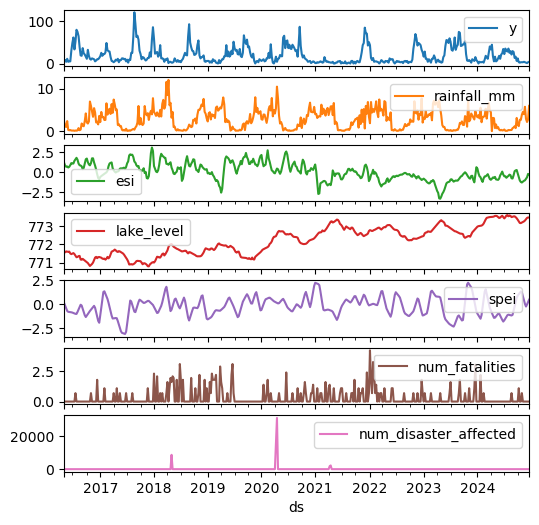

In [10]:
(
    df_weekly_for_model
    .drop(columns = ["unique_id"])
    .set_index("ds")
    .plot(subplots = True, figsize = (6, 6))
)

## Feature Engineering

### Create rolling datasets

Note that the rolling procedure includes the current timestamp so we need to drop the current value

In [11]:
lookback_period = 4
df_weekly_rolled = (
    roll_time_series(
        df_weekly_for_model.drop(columns=["y"]),
        column_id = "unique_id",
        column_sort = "ds",
        min_timeshift = lookback_period,
        max_timeshift = lookback_period
    )
    .drop(columns = ["unique_id"])
)

Rolling: 100%|██████████| 29/29 [00:02<00:00, 10.62it/s]


### Build features

In [12]:
feature_params = dict(
    abs_energy = None,
    absolute_maximum = None,
    absolute_sum_of_changes = None,
    augmented_dickey_fuller = [{"attr": "pvalue", "autolag": "AIC"}],
    change_quantiles = [{"f_agg": "mean", "isabs": False, "qh": 0.8, "ql": 0.2}],
    count_above_mean = None,
    count_below_mean = None,
    last_location_of_maximum = None,
    last_location_of_minimum = None,
    linear_trend_timewise = [{"attr": "slope"}],
    maximum = None,
    mean = None,
    mean_change = None,
    mean_abs_change = None,
    mean_second_derivative_central = None,
    median = None,
    minimum = None,
    kurtosis = None,
    sample_entropy = None,
    sum_values = None,
    variance_larger_than_standard_deviation = None
)


In [13]:
df_weekly_rolled.head()

,ds,rainfall_mm,esi,lake_level,spei,num_fatalities,num_disaster_affected,id
0,2016-05-06,2.305024,1.151677,771.531526,0.135361,0.0,0.0,"(1, 2016-06-03 00:00:00)"
1,2016-05-13,1.090120,0.782254,771.574944,-0.140963,0.0,0.0,"(1, 2016-06-03 00:00:00)"
2,2016-05-20,0.987415,0.660027,771.618171,-0.417286,0.0,0.0,"(1, 2016-06-03 00:00:00)"
3,2016-05-27,2.349879,0.691746,771.602400,-0.688308,0.0,0.0,"(1, 2016-06-03 00:00:00)"
4,2016-06-03,0.271620,0.566247,771.595700,-0.784358,0.0,0.0,"(1, 2016-06-03 00:00:00)"


In [14]:
df_features = (
    extract_features(
        df_weekly_rolled,
        column_id = "id",
        column_sort = "ds",
        # default_fc_parameters = feature_params
    )
    [lambda x: [c for c in x.columns if (x[c].isna().sum() == 0) & (x[c].std() > 0)]]
)

Feature Extraction: 100%|██████████| 30/30 [00:14<00:00,  2.03it/s]
/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [15]:
df_ts_all_model_features = (
    impute(df_features)
    .reset_index()
    .drop(columns = ["level_0"])
    .rename(columns = {"level_1": "ds"})
    .dropna(axis = 1)
    [lambda x: [c for c in x.columns if not (("friedrich" in c) or ("benford" in c) or ("langevin" in c))]]
)

### Reduce feature with correlation

In [16]:
ts_relevant_features = [df_ts_all_model_features.columns.tolist()[0]]
for f in df_ts_all_model_features.columns.tolist()[1:]:
    corrs = df_ts_all_model_features[ts_relevant_features + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.5:
        ts_relevant_features.append(f)   

In [17]:
df_ts_final_model_features = df_ts_all_model_features[ts_relevant_features]

In [18]:
df_ts_final_model_features.shape

(447, 204)

## Data for model

We use all the engineered features and add a few more manually. Then we'll let the models figure out which ones are most important.

In [19]:
df_all_data = (
    df_weekly
    .assign(
        week = lambda x: 0.5 * (1 + np.sin(2 * np.pi * (x["ds"].dt.isocalendar().week + 30) / 52)),
        rainfall_mm_sum_4w = lambda x: (sum([x["rainfall_mm"].shift(i) for i in range(1, 5)])),
        rainfall_mm_sum_8w = lambda x: (sum([x["rainfall_mm"].shift(i) for i in range(1, 9)])),
        esi_mean_4w = lambda x: (sum([x["esi"].shift(i) for i in range(1, 5)])/4),
        esi_mean_8w = lambda x: (sum([x["esi"].shift(i) for i in range(1, 9)])/8),
        lake_level_mean_4w = lambda x: (sum([x["lake_level"].shift(i) for i in range(1, 5)])/4),
        lake_level_mean_8w = lambda x: (sum([x["lake_level"].shift(i) for i in range(1, 9)])/8),
        spei_mean_4w = lambda x: (sum([x["spei"].shift(i) for i in range(1, 5)])/4),
        spei_mean_8w = lambda x: (sum([x["spei"].shift(i) for i in range(1, 9)])/8),
        num_fatalities_sum_4w = lambda x: (sum([x["num_fatalities"].shift(i) for i in range(1, 5)])),
        num_fatalities_sum_8w = lambda x: (sum([x["num_fatalities"].shift(i) for i in range(1, 9)])),
        num_disaster_affected_sum_4w = lambda x: (sum([x["num_disaster_affected"].shift(i) for i in range(1, 5)])),
        num_disaster_affected_sum_8w = lambda x: (sum([x["num_disaster_affected"].shift(i) for i in range(1, 9)])),
    )
    .pipe(
        lambda x: x.assign(
            **{
                f"{col}_{i}w": lambda x, col=col, i=i: x[col].shift(i) 
                for i in range(1, 9)
                for col in ["rainfall_mm", "esi", "lake_level", "spei", "num_fatalities", "num_disaster_affected"]
            }
        )
    )
    .drop(columns = [c for c in df_weekly.columns if c not in ["ds", "y", "unique_id"]])
    .merge(
        df_ts_final_model_features,
        how = "left",
        on = "ds"
    )
    .dropna()
    .reset_index(drop = True)
    .set_index("ds")
)
    

In [20]:
df_all_data = (
    df_all_data
    .pipe(
        lambda x: x.assign(
            **{
                num_col: lambda df_, num_col=num_col: df_[num_col].astype("float32") for num_col in x.select_dtypes(include = ["float64"]).columns
            }
        )
    )
)

## Train-validation-test split

In [21]:
X_train = df_all_data.loc[lambda x: x.index < TEST_START_DATE].drop(columns = ["y"])
y_train = df_all_data.loc[lambda x: x.index < TEST_START_DATE]["y"]
X_test = df_all_data.loc[lambda x: x.index >= TEST_START_DATE].drop(columns = ["y"])
y_test = df_all_data.loc[lambda x: x.index >= TEST_START_DATE]["y"]

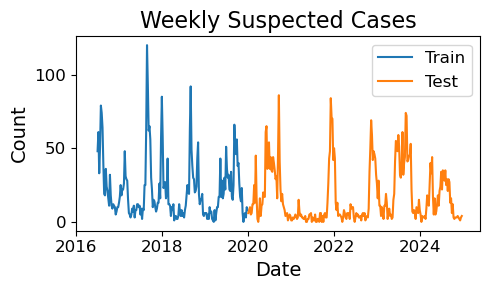

In [22]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(y_train.index, y_train, label="Train")
ax.plot(y_test.index, y_test, label="Test")
ax.legend(fontsize=12)
ax.set_title("Dataset Splits", fontsize=16)
ax.tick_params(labelsize = 12)
ax.set_title("Weekly Suspected Cases", fontsize = 16)
ax.set_xlabel("Date", fontsize = 14)
ax.set_ylabel("Count", fontsize = 14)
ax.set(xticks=["2016-01-01", "2018-01-01", "2020-01-01", "2022-01-01", "2024-01-01"])
ax.set_xticklabels(["2016", "2018", "2020", "2022", "2024"], fontsize = 12) 
plt.tight_layout()
plt.minorticks_off()
fig.align_ylabels()
plt.savefig(img_dir / "train_test_split.png", dpi = 300, bbox_inches = "tight")

## Data Preprocessing

In [23]:
max_abs_scaler = MaxAbsScaler()
X_train_scaled = max_abs_scaler.fit_transform(X_train)
X_test_scaled = max_abs_scaler.transform(X_test)

df_train = (
    pd.DataFrame(
        X_train_scaled, 
        columns = X_train.columns,
        index = X_train.index
    )
    .assign(
        y = y_train.values,
    )
    .reset_index()
)
df_test = (
    pd.DataFrame(
        X_test_scaled, 
        columns = X_test.columns,
        index = X_test.index
    )
    .assign(
        y = y_test.values,
    )
    .reset_index()
)

## Simple Correlation Analysis

In [24]:
corr_factors = (
    df_train
    .drop(columns = ["ds"])
    .corr()
    ["y"]
    .T
    .to_frame(name = "corr")
    .loc[lambda x: x.index != "y"]
    .loc[lambda x: x["corr"] >= 0.01]
    .sort_values(by = "corr", ascending = False, key = np.abs)
)

#### Extract features with low correlation

In [25]:
list_of_relevant_features_simple = [corr_factors.index.tolist()[0]]
for f in corr_factors.index.tolist()[1:]:
    corrs = df_train[list_of_relevant_features_simple + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.2:
        list_of_relevant_features_simple.append(f)    

In [26]:
len(list_of_relevant_features_simple)

30

In [27]:
corr_factors

,corr
week,0.433025
esi__c3__lag_1,0.430705
esi_1w,0.411691
esi__abs_energy,0.408632
esi_2w,0.391017
...,...
lake_level__fourier_entropy__bins_100,0.016865
"rainfall_mm__change_quantiles__f_agg_""mean""__isabs_False__qh_0.4__ql_0.0",0.016573
rainfall_mm__fourier_entropy__bins_100,0.016249
spei_mean_8w,0.015447


#### Final Dataset

In [28]:
df_reports_cov_corr_simple = (
    df_test
    .reset_index()
    [["ds", "y"] + list_of_relevant_features_simple]
    .assign(
        **{
            f"{feat}_corr": lambda x, feat=feat: x[feat] * corr_factors.loc[lambda x: x.index == feat, "corr"].values[0]
            for feat in list_of_relevant_features_simple
        }
    )
    .assign(
        cov = lambda x: np.exp(normalize(
            x
            [[c for c in x.columns if c.endswith("_corr")]]
            .sum(axis = 1)
        )),
        # y = lambda x: np.exp(x["y"]) - 1,
    )
    .merge(
        df_weekly[["ds", "idps", "num_disaster_affected"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [["date", "reports", "idps", "num_disaster_affected", "cov"]]
)
    

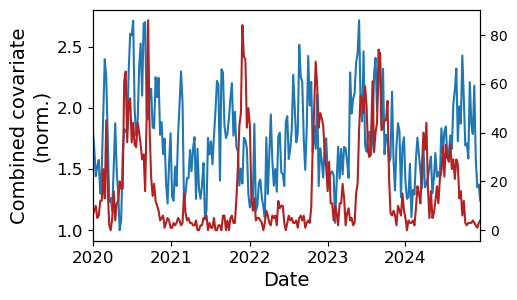

In [29]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_corr_simple
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_corr_simple
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate\n(norm.)", fontsize = 14)
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.tick_params(axis = "y", labelsize = 12)
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates.png", dpi = 300, bbox_inches = "tight")

## Model on Train Data

In [30]:
custom_scorer = make_scorer(
    custom_smape,
    greater_is_better = False,
)

log_transformer = FunctionTransformer(
    func = np.log1p,
    inverse_func = np.expm1,
)

### Lasso

#### Hyperparameter Search

In [31]:
# lasso_pipe = Pipeline([
#     ("lasso", TransformedTargetRegressor(regressor = Lasso(), transformer = log_transformer)),
# ])

# lasso_search = dict(
#     lasso__regressor__alpha = Real(0.001, 1000, "log-uniform"),
#     lasso__regressor__max_iter = Integer(2000, 30000),
#     lasso__regressor__tol = Real(1e-7, 1e-4, "log-uniform"),
# )

lasso_search = dict(
    alpha = Real(0.001, 1000, "log-uniform"),
    # max_iter = Integer(10, 3000),
    # tol = Real(1e-9, 1e-1, "log-uniform"),
)

# lasso_opt = BayesSearchCV(
#     lasso_pipe,
#     search_spaces = lasso_search,
#     random_state = seed,
#     scoring = "neg_max_error",
#     n_iter = 30,
#     n_jobs = -1,
#     return_train_score = True
# )
lasso_opt = BayesSearchCV(
    estimator = Lasso(max_iter = 1000, tol = 0.01),
    search_spaces = lasso_search,
    random_state = seed,
    scoring = "neg_max_error",
    n_iter = 30,
    n_jobs = -1,
    return_train_score = True
)

In [32]:
lasso_opt.fit(X_train_scaled, y_train)

BayesSearchCV(estimator=Lasso(tol=0.01), n_iter=30, n_jobs=-1,
              random_state=4183, return_train_score=True,
              scoring='neg_max_error',
              search_spaces={'alpha': Real(low=0.001, high=1000, prior='log-uniform', transform='normalize')})

In [33]:
lasso_opt.best_params_

OrderedDict([('alpha', 0.2735095336109356)])

In [34]:
lasso_opt.best_score_

-54.421756744384766

<Axes: title={'center': 'Convergence plot'}, xlabel='Number of calls $n$', ylabel='$\\min f(x)$ after $n$ calls'>

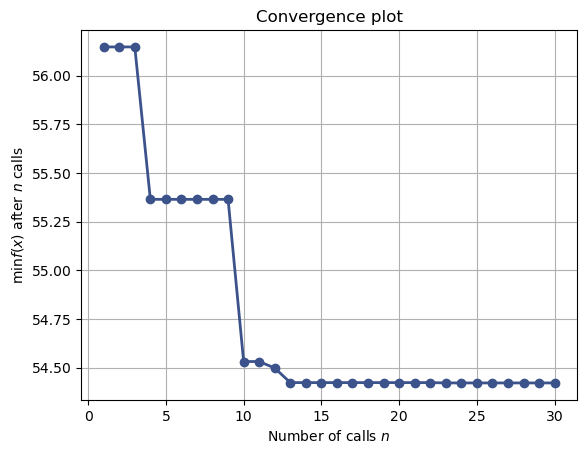

In [35]:
plot_convergence(lasso_opt.optimizer_results_[0])

<Axes: >

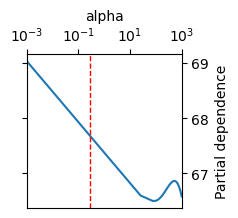

In [36]:
plot_objective(
    lasso_opt.optimizer_results_[0],
    dimensions = ["alpha"],
    n_minimum_search=int(1e8)
)

#### Predictions

In [37]:
lasso_best = lasso_opt.best_estimator_

##### Predict on train set

In [38]:
lasso_best_pred_train = lasso_best.predict(X_train_scaled)

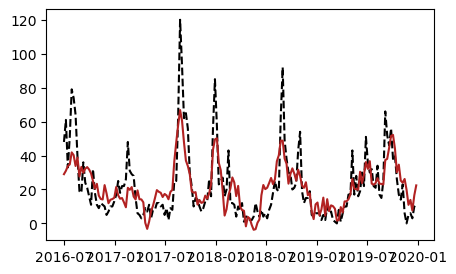

In [39]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    lasso_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [80]:
lasso_best = lasso_opt.best_estimator_
lasso_best_pred_test = (
    lasso_best.predict(X_test_scaled)
    .clip(min = 0)
)

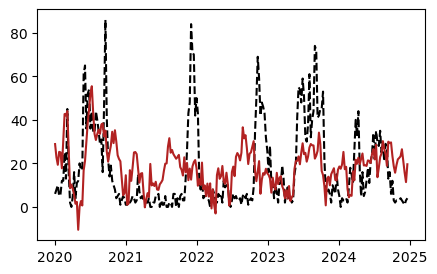

In [79]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_test.index,
    y_test,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_test.index,
    lasso_best_pred_test,
    label = "Validation",
    color = "firebrick"
)

#### Extract Model coefficients

In [42]:
df_lasso_coef = (
    pd.DataFrame(
        # lasso_best["lasso"].regressor_.coef_,
        lasso_best.coef_,
        index = X_train.columns,
        columns = ["coef"]
    )
    .loc[lambda x: np.abs(x["coef"]) > 0]
    .sort_values(by = "coef", ascending = False, key = np.abs)
)

In [43]:
df_lasso_coef.shape

(47, 1)

In [44]:
df_lasso_coef

,coef
rainfall_mm_sum_8w,-30.365522
esi__abs_energy,14.816244
lake_level__mean_abs_change,-14.367462
spei__mean_change,-9.296576
esi_1w,8.136165
esi__cid_ce__normalize_True,-5.985718
"esi__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.4",5.582635
esi__c3__lag_1,4.931357
"lake_level__change_quantiles__f_agg_""var""__isabs_True__qh_0.8__ql_0.0",-4.738086
"rainfall_mm__fft_coefficient__attr_""angle""__coeff_1",4.052462


#### Final Dataset

In [85]:
df_reports_cov_lasso = (
    df_test
    [["ds", "y"] + df_lasso_coef.index.tolist()]
    .assign(
        **{f"{feat}_lasso": lambda x, feat=feat: (
                x[feat] 
                * df_lasso_coef.loc[lambda x: x.index == feat, "coef"].values[0]
            )
            for feat in df_lasso_coef.index.tolist()
        }
    )
    .assign(
        cov = lambda x: normalize(
            # np.expm1(
            #     # lasso_best["lasso"].regressor_.intercept_ + 
            #     lasso_best.intercept_ +
            #     x[[c for c in x.columns if c.endswith("_lasso")]].sum(axis = 1)
            # )
            (
                # lasso_best["lasso"].regressor_.intercept_ + 
                lasso_best.intercept_ +
                x[[c for c in x.columns if c.endswith("_lasso")]].sum(axis = 1)
            )
        )
    )
    .merge(
        df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [["date", "reports", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop", "cov"] + df_lasso_coef.index.tolist()]
)

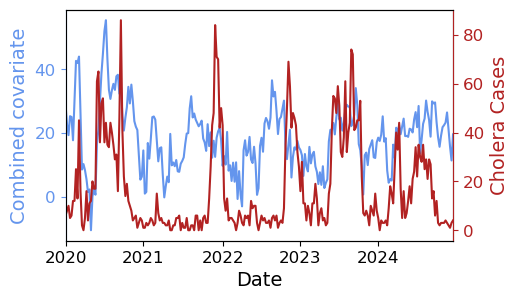

In [46]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_lasso
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_lasso
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
# ax.set_ylim(df_reports_cov_lasso["reports"].min(), df_reports_cov_lasso["reports"].max())
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

### XGBoost

#### Hyperparameter Search

In [47]:
xgb_pipe = Pipeline([
    (
        "xgb", 
        TransformedTargetRegressor(
            regressor = xgb.XGBRegressor(
                booster = "gblinear",
                objective = "reg:squarederror",
                random_state = seed
            ), 
            transformer = log_transformer
        )
    ),
])

# xgb_search = {
#     "learning_rate": Real(1e-5, 0.1, "log-uniform"),
#     "n_estimators": Integer(10, 5000),
#     # "max_depth": Integer(3, 10),
#     "alpha": Real(0.001, 1000, "log-uniform"),
#     # "objective": Categorical(["reg:squarederror", "reg:absoluteerror"]),
#     # "eval_metric": (["rmse", "mae", "rmsle", "mape", "logloss", "poisson-nloglik", "gamma-nloglik"]),
# }
# xgb_search = {
#     "xgb__regressor__learning_rate": Real(1e-5, 0.1, "log-uniform"),
#     "xgb__regressor__n_estimators": Integer(10, 1000),
#     # "max_depth": Integer(3, 10),
#     "xgb__regressor__alpha": Real(0.01, 1000, "log-uniform"),
#     # "xgb__regressor__objective": Categorical(["reg:squarederror", "reg:absoluteerror"]),
#     # "xgb__regressor__eval_metric": (["rmse", "mae", "rmsle", "mape", "logloss", "poisson-nloglik", "gamma-nloglik"]),
# }
# xgb_search = dict(
#     xgb__regressor__learning_rate=lognorm(scale=np.exp(0.1), s = 1),
#     xgb__regressor__n_estimators=randint(10, 1000),
#     xgb__regressor__alpha=lognorm(scale=np.exp(0.3), s = 5)
# )
xgb_search = dict(
    learning_rate=np.logspace(-5, -1, 20),
    n_estimators=np.arange(100, 500, 20),
    alpha=np.logspace(-2, 1, 20),
)
# xgb_search = dict(
#     xgb__regressor__learning_rate=np.logspace(-5, -1, 10),
#     xgb__regressor__n_estimators=np.arange(100, 500, 50),
#     xgb__regressor__alpha=np.logspace(-2, 1, 10),
#     # xgb__regressor__reg_lambda=np.logspace(-2, 2, 10),
#     # min_split_loss=np.arange(1, 10, 2),
#     # max_depth=np.arange(3, 10, 1)
# )

# xgb_opt = BayesSearchCV(
# xgb_opt = RandomizedSearchCV(
#     # estimator = xgb_pipe,
#     estimator = xgb.XGBRegressor(
#         booster = "gblinear",
#         objective = "reg:squarederror",
#         eval_metric = custom_scorer,
#         random_state = seed
#     ),
#     param_distributions = xgb_search,
#     random_state = seed,
#     # scoring = custom_scorer,
#     n_iter = 30,
#     n_jobs = -1,
#     cv = 3,
#     return_train_score = True
# )
xgb_opt = GridSearchCV(
    # estimator = xgb_pipe,
    estimator = xgb.XGBRegressor(
        booster = "gblinear",
        objective = "reg:squarederror",
        # eval_metric = custom_scorer,
        random_state = seed
    ),
    param_grid = xgb_search,
    scoring = "neg_max_error",
    n_jobs = -1,
    cv = 3,
    return_train_score = True
)

In [48]:
xgb_opt.fit(X_train_scaled, y_train.values)

GridSearchCV(cv=3,
             estimator=XGBRegressor(base_score=None, booster='gblinear',
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=...
       6.95192796e-05, 1.12883789e-04, 1.83298071e-04, 2.97635144e-04,
       4.83293024e-04, 7.84759970e-04, 1.27427499e-03, 2.06913808e-03,
       3.35981829e-03, 5.45559478e-03, 8.85866790e-03, 1.43844989e-02,
       2.33572147e-02, 3.79269019e-02, 6.15848211e-02, 1.00000000e-01]),
                         'n_estimators': array([100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300, 320, 340,
       360, 380, 400, 420, 440, 460, 480])},
             return_train_score=True, scoring='neg_max_error')

In [49]:
xgb_opt.best_score_

-52.01195526123047

In [50]:
xgb_opt.best_params_

{'alpha': 0.08858667904100823,
 'learning_rate': 0.01438449888287663,
 'n_estimators': 360}

#### Predictions

In [51]:
xgb_best = xgb_opt.best_estimator_

##### Predictions on train set

In [52]:
xgb_best_pred_train = xgb_best.predict(X_train_scaled)

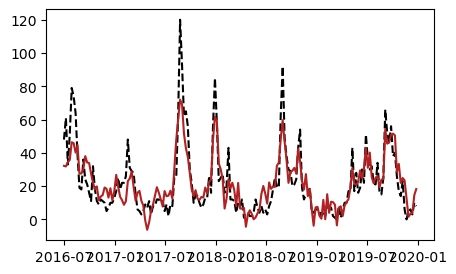

In [53]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    xgb_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [54]:
xgb_best_pred = (
    xgb_best.predict(X_test_scaled)
    .clip(min = 0)
)

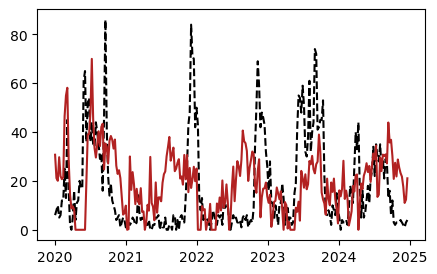

In [55]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_test.index,
    y_test,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_test.index,
    xgb_best_pred,
    label = "Validation",
    color = "firebrick"
)

#### Extract Model coefficients

In [56]:
df_xgb_coef = (
    pd.DataFrame(
        # np.c_[X_train.columns, xgb_best["xgb"].regressor_.coef_],
        np.c_[X_train.columns, xgb_best.coef_],
        columns = ["feature", "coef"]
    )
    .loc[lambda x: np.abs(x["coef"]) > 0]
    .sort_values(by = "coef", ascending = False, key = np.abs)
)

In [57]:
df_xgb_coef.shape

(242, 2)

In [58]:
xgb_relevant_features = [df_xgb_coef["feature"].values.tolist()[0]]
for f in df_xgb_coef["feature"].values.tolist()[1:]:
    corrs = df_train[xgb_relevant_features + [f]].corr()[f].abs()
    if corrs[:-1].max() < 0.5:
        xgb_relevant_features.append(f)   

In [59]:
len(xgb_relevant_features)

169

<Axes: >

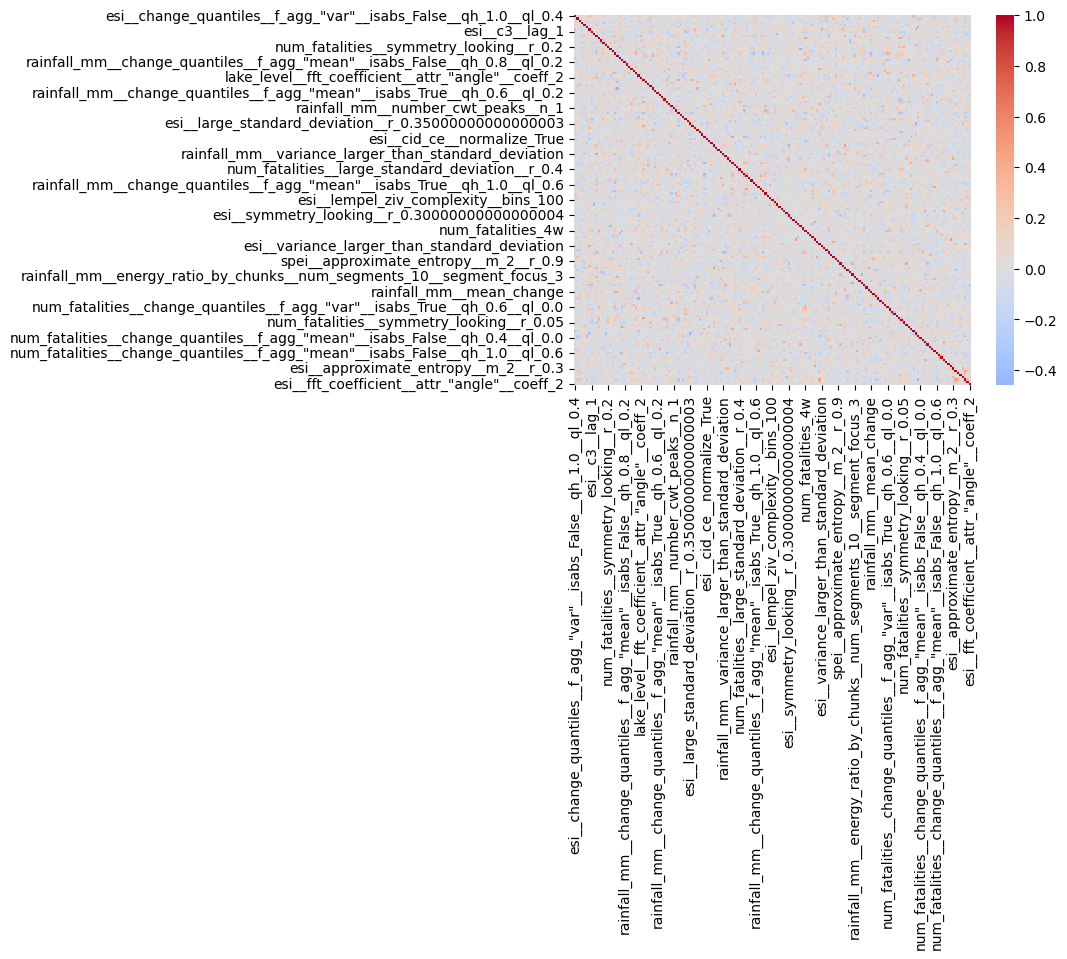

In [60]:
sns.heatmap(
    df_train
    [xgb_relevant_features]
    .corr(),
    center = 0,
    cmap = "coolwarm",
)

#### Final Dataset

In [61]:
df_reports_cov_xgb = (
    df_test
    [["ds", "y"] + df_xgb_coef["feature"].tolist()]
    .assign(
        **{
            f"{feat}_xgb": lambda x, feat=feat: x[feat] * df_xgb_coef.loc[lambda x: x["feature"] == feat, "coef"].values[0]
            for feat in df_xgb_coef["feature"].tolist()
        }
    )
    .assign(
        cov = lambda x: normalize(
            xgb_best.intercept_ +
            # xgb_best["xgb"].regressor_.intercept_ + 
            x[[c for c in x.columns if c.endswith("_xgb")]].sum(axis = 1)
        )
    )
    .merge(
        df_weekly[["ds", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [
        [
            "date", 
            "reports", 
            "rdt_confirmed", 
            "idps", 
            "num_disaster_affected", 
            "vacc_1", 
            "vacc_1_prop",
            "vacc_2",
            "vacc_2_prop",
            "cov"
        ] + df_xgb_coef["feature"].tolist()
    ]
)

/var/folders/t5/wdgbs_cn20j1h277s6rs9ckw0000gp/T/ipykernel_21254/2534193223.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test
/var/folders/t5/wdgbs_cn20j1h277s6rs9ckw0000gp/T/ipykernel_21254/2534193223.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test
/var/folders/t5/wdgbs_cn20j1h277s6rs9ckw0000gp/T/ipykernel_21254/2534193223.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

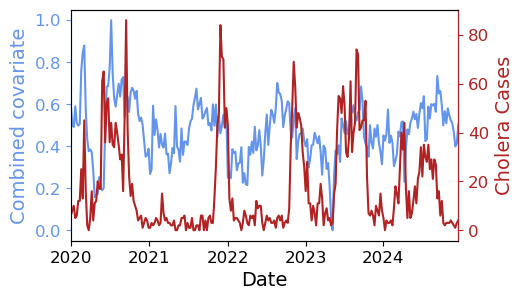

In [62]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_xgb
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_xgb
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

### Best non-interpretable model

#### Hyperparameter Search

In [63]:
xgbtree_pipe = Pipeline([
    (
        "xgb", 
        TransformedTargetRegressor(
            regressor = xgb.XGBRegressor(
                objective = "reg:squarederror",
                min_split_loss = 1,
                n_estimators = 200,
                #  learning_rate = 0.19,
                #  alpha = 2,
                #  reg_lambda = 11,
                max_depth = 2,
                random_state = seed

            ), 
            transformer = log_transformer
        )
    ),
])
# xgbtree_search = dict(
#     # xgb__regressor__learning_rate=np.logspace(-5, -1, 5),
#     xgbtree_pipe__regressor__learning_rate=np.linspace(0.15, 0.25, 10),
#     # xgb__regressor__n_estimators=np.arange(100, 500, 100),
#     # xgb__regressor__alpha=np.logspace(-2, 1, 5),
#     xgb__regressor__alpha=np.linspace(1, 3, 10),
#     # xgb__regressor__reg_lambda=np.logspace(-2, 2, 5),
#     xgb__regressor__reg_lambda=np.linspace(5, 20, 10),
#     # xgb__regressor__min_split_loss=np.arange(1, 5, 2),
#     # xgb__regressor__max_depth=np.arange(3, 5, 1)
# )

xgbtree_search = dict(
    learning_rate=np.logspace(-1, 1, 10),
    # learning_rate = np.linspace(1e-2, 0.2, 10),
    alpha=np.logspace(-2, 1, 10),
    # alpha = np.linspace(1e-1, 10, 10),
    reg_lambda=np.logspace(0, 2, 10),
    # reg_lambda = np.linspace(5, 500, 10),
    # min_split_loss=np.arange(1, 5, 2),
    # max_depth=np.arange(1, 10, 2)
)

xgbtree_best = GridSearchCV(
    #estimator = xgbtree_pipe,
    estimator = xgb.XGBRegressor(
         # eval_metric = custom_scorer,
         min_split_loss = 3,
         n_estimators = 300,
        #  learning_rate = 0.1,
        #  alpha = 2,
        #  reg_lambda = 11,
         max_depth = 1,
         random_state = seed
    ),
    param_grid = xgbtree_search,
    scoring = "neg_max_error",
    n_jobs = -1,
    cv = 3,
    return_train_score = True
)

In [64]:
xgbtree_best.fit(X_train_scaled, y_train.values)

/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 388, in _score
 

GridSearchCV(cv=3,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
             param_grid={'alpha': array([ 0.01      ,  0.02154435,  0.04641589,  0.1       ,  0.21544347,
        0.46415888,  1.        ,  2.15443469,  4.64158883, 10.        ]),
                         'learning_rate': array([ 0.1       ,  0.16681005,  0.27825594,  0.46415888,  0.77426368,
        1.29154967,  2.15443469,  3.59381366,  5.9948425 , 10.        ]),
                         'reg_lambda': array([  1.        ,   1.66810054,   2.7825594 ,   4.64158883,
         7.74263683,  12.91549665,  21.5443469 ,  35.93813664,
        59.94842503, 100.        ])},
             return_train_score=True, scoring='neg_max_error')

In [65]:
xgbtree_best.best_score_

-53.34832572937012

In [66]:
xgbtree_best.best_params_

{'alpha': 0.21544346900318834,
 'learning_rate': 0.2782559402207124,
 'reg_lambda': 1.0}

#### Predictions

In [67]:
xgbtree_best = xgbtree_best.best_estimator_

##### Predictions on train set

In [68]:
xgbtree_best_pred_train = xgbtree_best.predict(X_train_scaled)

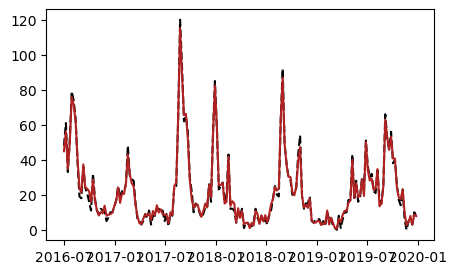

In [69]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_train.index,
    y_train,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_train.index,
    xgbtree_best_pred_train,
    label = "Validation",
    color = "firebrick"
)

##### Predict on test set

In [70]:
xgbtree_best_pred_test = (
    xgbtree_best.predict(X_test_scaled)
    .clip(min = 0)
)

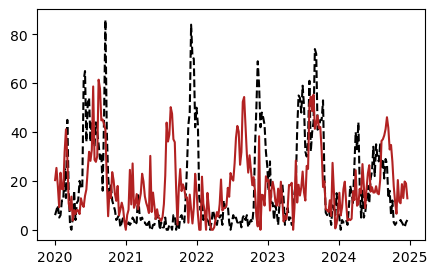

In [71]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(
    y_test.index,
    y_test,
    label = "Data",
    color = "black",
    linestyle = "--"
)
ax.plot(
    y_test.index,
    xgbtree_best_pred_test,
    label = "Validation",
    color = "firebrick"
)

#### SHAP coefficients

In [72]:
xgbtree_explainer = shap.Explainer(xgbtree_best)

In [73]:
xgb_shap = xgbtree_explainer(df_test.drop(columns = ["ds", "y"]))

In [74]:
df_xgbtree_shap = (
    pd.DataFrame(
        data = xgb_shap.values,
        columns = xgb_shap.feature_names,
    )
)

Text(0.5, 1.0, 'Gradient Boosting Regressor SHAP Values')

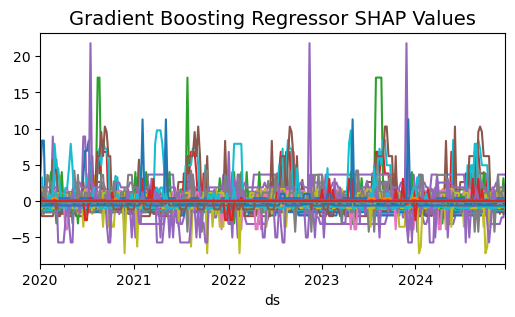

In [75]:
fig, ax = plt.subplots(figsize=(6, 3))
(
    pd.concat([df_test["ds"], df_xgbtree_shap], axis = 1)
    .set_index("ds")
    .plot(legend=False, ax=ax)
)
ax.set_title("Gradient Boosting Regressor SHAP Values", fontsize = 14)

#### Final Dataset

In [ ]:
df_reports_cov_xgbtree = (
    pd.concat([df_test[["ds"]], df_xgbtree_shap], axis = 1)
    .set_index("ds")
    .assign(
        cov = lambda x: normalize(
            x.sum(axis = 1)
        )
    )
    .reset_index()
    .merge(
        df_weekly[["ds", "y", "rdt_confirmed", "idps", "num_disaster_affected", "vacc_1", "vacc_1_prop", "vacc_2", "vacc_2_prop"]],
        on = "ds",
        how = "left"
    )
    .rename(
        columns = {
            "ds": "date",
            "y": "reports"
        }
    )
    [
        [
            "date", 
            "reports", 
            "rdt_confirmed", 
            "idps", 
            "num_disaster_affected", 
            "vacc_1", 
            "vacc_1_prop",
            "vacc_2",
            "vacc_2_prop",
            "cov"
        ]
    ]
)

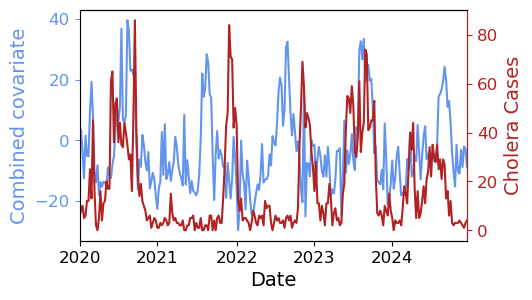

In [77]:
fig, ax = plt.subplots(figsize=(5, 3))
(
    df_reports_cov_xgbtree
    .set_index("date")
    .plot(
        y = "cov",
        ax = ax, 
        color = "cornflowerblue",
        legend = False
    )
)
ax2 = ax.twinx()
(
    df_reports_cov_xgbtree
    .set_index("date")
    .plot(
        y = "reports",
        ax = ax2, 
        legend = False,
        color = "firebrick"
    )
)
ax.set_ylabel("Combined covariate", fontsize = 14, color = "cornflowerblue")
ax.set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
ax.set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
ax.set_xlabel("Date", fontsize = 14)
ax.spines["left"].set_color("cornflowerblue")
ax.tick_params(axis = "y", color = "cornflowerblue", labelsize = 12, labelcolor = "cornflowerblue")
ax2.set_ylabel("Cholera Cases", fontsize = 14, color = "firebrick")
ax2.spines["right"].set_color("firebrick")
ax2.tick_params(axis = "y", color = "firebrick", labelsize = 12, labelcolor = "firebrick")
plt.minorticks_off()
plt.savefig(img_dir / "combined_covariates_and_cholera.png", dpi = 300, bbox_inches = "tight")

## Output Data

In [86]:
df_reports_cov = df_reports_cov_lasso.copy()

In [82]:
df_reports_cov.head()

,date,reports,rdt_confirmed,idps,num_disaster_affected,vacc_1,vacc_1_prop,vacc_2,vacc_2_prop,cov,...,rainfall_mm__variance_larger_than_standard_deviation,esi__number_crossing_m__m_1,spei__large_standard_deviation__r_0.35000000000000003,lake_level__large_standard_deviation__r_0.35000000000000003,rainfall_mm__autocorrelation__lag_2,esi__lempel_ziv_complexity__bins_3,esi_mean_4w,spei_4w,esi__large_standard_deviation__r_0.35000000000000003,num_fatalities_7w
0,2020-01-03,6,0,0.0,0.0,0.0,0.0,0.0,0.0,28.890804,...,0.0,0.333333,1.0,0.0,-0.024933,0.75,0.604868,0.265974,1.0,0.0
1,2020-01-10,8,1,0.0,0.0,0.0,0.0,0.0,0.0,22.772903,...,0.0,0.333333,1.0,1.0,-0.534484,1.00,0.763823,0.106493,1.0,0.0
2,2020-01-17,10,1,0.0,0.0,0.0,0.0,0.0,0.0,19.369738,...,0.0,0.333333,1.0,1.0,-0.877637,1.00,0.795520,-0.052988,1.0,0.0
3,2020-01-24,5,1,-9742.0,0.0,0.0,0.0,0.0,0.0,25.317940,...,0.0,0.333333,1.0,1.0,-0.856536,0.75,0.695170,-0.207273,1.0,0.0
4,2020-01-31,6,1,0.0,0.0,0.0,0.0,0.0,0.0,25.072275,...,0.0,0.333333,1.0,0.0,-0.953673,1.00,0.563368,-0.190061,1.0,0.0


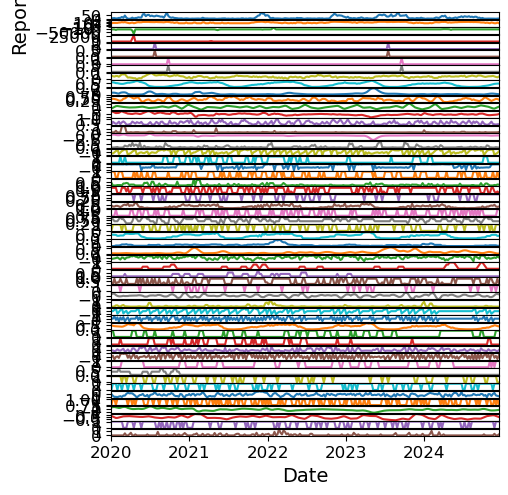

In [87]:
axes = df_reports_cov.set_index("date").plot(subplots = True, legend = False, figsize = (5, 5.5))
axes[0].set_ylabel("Reports", fontsize = 14)
axes[1].set_yscale("symlog")
axes[1].set(yticks=[-10000, -100, 0, 100, 10000])
axes[1].set_ylim(-150000, 150000)
axes[-1].set(xticks=["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"])
axes[-1].set_xticklabels(["2020", "2021", "2022", "2023", "2024"], fontsize = 12) 
axes[-1].set_xlabel("Date", fontsize = 14)
for ax in axes:
    ax.tick_params(axis = "y", labelsize = 12)
plt.minorticks_off()
plt.subplots_adjust(hspace = 0.1)
fig = axes[0].get_figure()
fig.align_ylabels(axes)
plt.savefig(img_dir / "model_data.png", dpi = 300, bbox_inches = "tight")

In [88]:
OUTPUT_FILEDATE = pd.Timestamp("today").strftime("%Y%m%d")
df_reports_cov.to_csv(processed_data_dir / f"uvira_chol_cov_week_{OUTPUT_FILEDATE}.csv", index=False)